# Track 01.2 — Text Cleaning, Normalization, and Chunking Strategies

> **RAG Engineering Academy | Track 01 — Ingestion & Chunking**  
> **Prerequisites:** Track 01.1 (PDF Parsing & High-Fidelity Document Ingestion)  
> **Execution Mode:** 100% Offline, Deterministic, Zero Synthetic Data Factories, Pure Python

---

## 🎯 Executive Overview & Architectural Motivation

In Track 01.1, we mastered raw document extraction and observed that raw parser output is rarely ready for vectorization. Real-world documents contain severe **ingestion artifacts**:
1. **Unicode Ligatures & Encoding Discrepancies:** Typesetting systems merge characters like `ﬁ` (`U+FB01`) or `ﬂ` (`U+FB02`). Decomposed accents (`e` + `́`) differ in byte sequence from precomposed characters (`é`).
2. **Invisible Non-Printable Artifacts:** Non-breaking spaces (` `), soft hyphens (`­`), and zero-width joiners (`​`) silently perturb tokenizers.
3. **Hyphenated Line Breaks:** Column-justified print splits words across lines (`algo-
rithm`), but naive replacement damages valid compounds (`state-of-the-art`).
4. **Erratic Whitespace:** Inconsistent line breaks and tabs break paragraph structure.

Once cleaned, unstructured text cannot simply be embedded whole. Embedding models have fixed context windows, and large texts suffer from the **"Lost-in-the-Middle"** degradation phenomenon. We must partition documents into semantically coherent **chunks**.

```mermaid
flowchart TD
    Raw["Raw Extracted Text (PDF/HTML/OCR)"] --> UnicodeNorm["1. Unicode NFKC Normalization"]
    UnicodeNorm --> Invisibles["2. Invisible Artifact & Control Stripping"]
    Invisibles --> Dehyphen["3. Context-Aware De-hyphenation"]
    Dehyphen --> WhiteNorm["4. Whitespace & Newline Standardization"]
    WhiteNorm --> CleanDoc["Clean Canonical Document"]
    
    CleanDoc --> Branch{"Chunking Strategy Selection"}
    Branch -->|"Sliding Window"| Fixed["Fixed-Size with Overlap"]
    Branch -->|"Syntactic Hierarchy"| Recursive["Recursive Character Splitter"]
    Branch -->|"Thematic Transitions"| Semantic["Semantic Boundary Heuristics"]
    
    Fixed --> Evaluate["Quantitative Comparison & Diagnostic Plotting"]
    Recursive --> Evaluate
    Semantic --> Evaluate
    Evaluate --> VectorReady["Indexed Chunks for Vector Store"]
```

In this notebook, we implement text cleaning pipelines, character-versus-token estimation, and three core chunking architectures from first principles.


### Step 1: Environment & Module Setup

We verify our local Python 3.12 virtual environment and import standard library utilities (`re`, `unicodedata`, `math`) alongside `numpy` and `matplotlib`.

No network connections or remote API keys are required. All transformations and heuristic algorithms run 100% locally and deterministically.


In [1]:
import sys
import os
import re
import math
import unicodedata
from pathlib import Path
from typing import List, Dict, Any, Tuple, Optional

import numpy as np
import matplotlib.pyplot as plt

print(f"Python executable: {sys.executable}")
print(f"Python version:    {sys.version.split()[0]}")
print(f"NumPy version:     {np.__version__}")

# Configure clean plotting defaults
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (11, 4.8)
plt.rcParams["figure.dpi"] = 120


Python executable: /Users/bharathm/Documents/Self Learning/RAG_from_scratch/.venv312/bin/python
Python version:    3.12.13
NumPy version:     2.5.4


### Step 2: The Raw Ingestion Artifact Problem & Unicode Normalization

Document parsers frequently emit typography glyphs and varying Unicode compositions:
- **Ligatures:** Typesetting software joins consecutive glyphs into single codepoints (`ﬁ` U+FB01, `ﬂ` U+FB02, `ﬃ` U+FB03). Subword tokenizers (BPE / WordPiece) may map these to `<unk>` or rare token IDs, destroying retrieval recall for common words like "filter" or "flow".
- **Canonical Composition Forms:**
  - `NFC` (Normalization Form C): Canonical Decomposition followed by Canonical Composition.
  - `NFD` (Normalization Form D): Canonical Decomposition into base glyphs and combining marks.
  - `NFKC` (Normalization Form KC): **Compatibility Decomposition** followed by Canonical Composition.
  - `NFKD` (Normalization Form KD): Compatibility Decomposition without recomposition.

**Why NFKC is Essential for RAG:**  
NFKC resolves compatibility glyphs—including typographic ligatures (`ﬁ` $\to$ `fi`), superscripts (`²` $\to$ `2`), and fullwidth characters (`１２３` $\to$ `123`)—into standard ASCII/Unicode equivalents while preserving standard letter casing.


In [2]:
# Demonstrate Unicode Normalization discrepancies
raw_ligature_sample = "The ﬁrst step is to conﬁgure the ﬂowchart with 10² units."
decomposed_accent = "caf" + "e\u0301"  # 'e' + combining acute accent
precomposed_accent = "caf\u00e9"

print("--- Ligature Resolution via NFKC ---")
print(f"Raw string:          {raw_ligature_sample!r}")
print(f"Length raw:          {len(raw_ligature_sample)}")
print(f"Raw codepoints:      {[hex(ord(c)) for c in raw_ligature_sample[:10]]}")

nfc_result = unicodedata.normalize("NFC", raw_ligature_sample)
nfkc_result = unicodedata.normalize("NFKC", raw_ligature_sample)

print(f"NFC Normalized:      {nfc_result!r} (Length: {len(nfc_result)})")
print(f"NFKC Normalized:     {nfkc_result!r} (Length: {len(nfkc_result)})")

print("\n--- Decomposed vs Precomposed Accent Equivalence ---")
print(f"Decomposed ('caf' + '\\u0301'): {decomposed_accent!r} (len: {len(decomposed_accent)})")
print(f"Precomposed ('caf\\u00e9'):       {precomposed_accent!r} (len: {len(precomposed_accent)})")
print(f"Direct string equality:       {decomposed_accent == precomposed_accent}")

nfc_decomp = unicodedata.normalize("NFC", decomposed_accent)
nfc_precomp = unicodedata.normalize("NFC", precomposed_accent)
print(f"Equality after NFC normalize: {nfc_decomp == nfc_precomp}")


--- Ligature Resolution via NFKC ---
Raw string:          'The ﬁrst step is to conﬁgure the ﬂowchart with 10² units.'
Length raw:          57
Raw codepoints:      ['0x54', '0x68', '0x65', '0x20', '0xfb01', '0x72', '0x73', '0x74', '0x20', '0x73']
NFC Normalized:      'The ﬁrst step is to conﬁgure the ﬂowchart with 10² units.' (Length: 57)
NFKC Normalized:     'The first step is to configure the flowchart with 102 units.' (Length: 60)

--- Decomposed vs Precomposed Accent Equivalence ---
Decomposed ('caf' + '\u0301'): 'café' (len: 5)
Precomposed ('caf\u00e9'):       'café' (len: 4)
Direct string equality:       False
Equality after NFC normalize: True


### Step 3: Whitespace Hygiene, Invisible Artifacts & De-hyphenation

Extracted text regularly contains layout noise:
1. **Invisible control characters:**
   - Non-breaking spaces (`\u00a0` or `\xa0`)
   - Zero-width spaces (`\u200b`), zero-width joiners (`\u200c`, `\u200d`), and byte-order marks (`\ufeff`)
   - Soft hyphens (`\u00ad`)
2. **Line-wrap hyphenation:**
   Justified columns break words across lines:
   ```text
   The retrieval-augmented generation archi-
   tecture requires careful evaluation.
   ```
   If concatenated verbatim, this produces `"archi- tecture"` or `"archi-tecture"`. However, a naive global replace of `"-"` with `""` would mutilate genuine compounds such as `"state-of-the-art"`, `"cost-effective"`, or `"parent-child"`.

We design targeted regexes to:
- Strip invisible non-printable artifacts.
- Repair line-broken words where a lowercase continuation immediately follows: `(\w+)-\n(\w+)` $\to$ `\1\2`.
- Standardize newline sequences (`\r\n` $\to$ `\n`) and collapse extraneous whitespace.


In [3]:
def repair_line_hyphenation(text: str) -> str:
    """Recombines words split across line breaks by hyphens while preserving compounds."""
    # Case 1: Word break hyphen at end of line followed by lowercase word continuation
    # e.g., 'trans-\nformer' -> 'transformer'
    text = re.sub(r'(\b[a-zA-Z]+)-\s*\n\s*([a-z]+[a-zA-Z]*\b)', r'\1\2', text)
    
    # Case 2: Intentional hyphenated compound split across lines
    # e.g., 'state-\nof-the-art' -> 'state-of-the-art'
    text = re.sub(r'(\b[a-zA-Z]+-)\s*\n\s*([a-zA-Z]+\b)', r'\1\2', text)
    return text

def strip_invisible_artifacts(text: str) -> str:
    """Removes non-breaking spaces, zero-width spaces, and non-printable control codes."""
    # Standardize non-breaking space
    text = text.replace('\u00a0', ' ').replace('\xa0', ' ')
    # Strip soft hyphens, zero-width spaces, BOM
    text = re.sub(r'[\u00ad\u200b\u200c\u200d\ufeff]', '', text)
    # Remove control characters except newline and tab
    text = re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]', '', text)
    return text

def normalize_whitespace(text: str) -> str:
    """Standardizes line endings, collapses blank lines, and trims redundant spacing."""
    text = text.replace('\r\n', '\n').replace('\r', '\n')
    # Limit consecutive blank lines to at most 2 (preserving markdown paragraph breaks)
    text = re.sub(r'\n{3,}', '\n\n', text)
    # Collapse multiple inline spaces and tabs
    text = re.sub(r'[ \t]+', ' ', text)
    lines = [line.strip() for line in text.split('\n')]
    return '\n'.join(lines).strip()

# Verification test on sample corrupted string
corrupted_sample = (
    "RAG pipelines rely on high-\nperformance vector index-\ning to prevent "
    "infor-\u00ad\nmation loss.\u200b\n\n\n\n"
    "The state-\nof-the-art models handle multi-\nmodal embeddings with ease.\xa0 "
)

cleaned_demo = normalize_whitespace(
    repair_line_hyphenation(
        strip_invisible_artifacts(
            unicodedata.normalize("NFKC", corrupted_sample)
        )
    )
)

print("Original Raw String:")
print(repr(corrupted_sample))
print("\nCleaned & Normalized String:")
print(repr(cleaned_demo))
print("\nRendered Output:\n" + cleaned_demo)


Original Raw String:
'RAG pipelines rely on high-\nperformance vector index-\ning to prevent infor-\xad\nmation loss.\u200b\n\n\n\nThe state-\nof-the-art models handle multi-\nmodal embeddings with ease.\xa0 '

Cleaned & Normalized String:
'RAG pipelines rely on highperformance vector indexing to prevent information loss.\n\nThe stateof-the-art models handle multimodal embeddings with ease.'

Rendered Output:
RAG pipelines rely on highperformance vector indexing to prevent information loss.

The stateof-the-art models handle multimodal embeddings with ease.


### Step 4: Building a Reusable Production Cleaning Pipeline

Now we combine these operations into a modular `TextCleaner` class.

In enterprise RAG systems, the text cleaning pipeline must satisfy three properties:
1. **Determinism:** Identical input always yields identical canonical output.
2. **Configurability:** Independent flags for unicode normalization, hyphen repair, and whitespace sanitization.
3. **Linear Performance:** $O(N)$ execution over document length without memory bloat.

We also construct a realistic document fixture representing an enterprise RAG architecture specification with deliberate noise to use throughout our chunking benchmarks.


In [4]:
class TextCleaner:
    """Modular text normalization and cleaning pipeline for RAG ingestion."""
    
    def __init__(
        self,
        normalize_unicode: bool = True,
        unicode_form: str = "NFKC",
        strip_invisibles: bool = True,
        repair_hyphens: bool = True,
        clean_whitespace: bool = True,
    ):
        self.normalize_unicode = normalize_unicode
        self.unicode_form = unicode_form
        self.strip_invisibles = strip_invisibles
        self.repair_hyphens = repair_hyphens
        self.clean_whitespace = clean_whitespace

    def clean(self, text: str) -> str:
        if not text:
            return ""
        if self.normalize_unicode:
            text = unicodedata.normalize(self.unicode_form, text)
        if self.strip_invisibles:
            text = strip_invisible_artifacts(text)
        if self.repair_hyphens:
            text = repair_line_hyphenation(text)
        if self.clean_whitespace:
            text = normalize_whitespace(text)
        return text

# Initialize pipeline
cleaner = TextCleaner()

# Realistic shared document fixture (Technical RAG Architecture Document)
RAW_DOCUMENT_FIXTURE = """
# Enterprise RAG Architectural Standards

Retrieval-Augmented Generation (RAG) augments large language models with dynamic exter-\nnal 
knowledge sources. By indexing domain-speciﬁc documents into vector databases, systems 
mitigate hallucina-\ntions and overcome model training cut-off limits.

## 1. Document Ingestion Lifecycle
The document ingestion subsystem processes heterogeneous source formats including PDF, 
Markdown, HTML, and unstructured docu-\nments. High-ﬁdelity spatial parsing extracts both 
running textual narrative and tabular schemas. 

Text normali-\nzation strips typesetting ligatures, resolves inconsistent encoding schemes, 
and repairs words severed by line-break hyphens. Without meticulous cleaning, downstream 
dense retrievers suﬀer substantial embedding drift.

## 2. Vector Indexing & Search Mechanics
Once text is segmented into discrete passages, dense embedding models project each chunk 
into a shared continuous semantic vector space. Approximate Nearest Neighbor (ANN) search 
algorithms, such as Hierarchical Navigable Small World (HNSW) graphs, retrieve top-k passages 
with sub-50ms latency.

Hybrid search schemes combine dense semantic vectors with sparse BM25 term-frequency 
indices. This fusion ensures exact matches for specialized domain keywords while preserving 
broad conceptual recall.

## 3. Context Assembly & Inference Guardrails
The final orchestration stage formats retrieved passages into an explicit context window 
for the generative model. Prompt templates must balance comprehensive context against 
positional attenuation, ensuring critical facts are not obscured within the middle of the prompt.
"""

CLEANED_DOCUMENT = cleaner.clean(RAW_DOCUMENT_FIXTURE)
print(f"Raw fixture length:     {len(RAW_DOCUMENT_FIXTURE)} characters")
print(f"Cleaned fixture length: {len(CLEANED_DOCUMENT)} characters")
print("\n--- Cleaned Preview (first 280 characters) ---")
print(CLEANED_DOCUMENT[:280] + "...")


Raw fixture length:     1659 characters
Cleaned fixture length: 1638 characters

--- Cleaned Preview (first 280 characters) ---
# Enterprise RAG Architectural Standards

Retrieval-Augmented Generation (RAG) augments large language models with dynamic external
knowledge sources. By indexing domain-specific documents into vector databases, systems
mitigate hallucinations and overcome model training cut-off ...


### Step 5: The Chunking Dilemma — Granularity, Context & Token Limits

Embedding models have hard token limits (e.g., 512, 1024, or 8192 tokens) and calculate dense vector representations by pooling attention over all input tokens. If an entire document is embedded as one single passage:
- Specific factual details are diluted across thousands of irrelevant words.
- Retrieval similarity scores suffer from regression to the mean.

#### The Granularity Spectrum
```text
[Single Sentence] <------------------- Optimal RAG -------------------> [Whole Document]
  High Precision                        300 - 800 Chars                   High Coherence
  Zero Context / Antecedents            Self-Contained Thoughts           Diluted Embeddings
```

#### Characters vs. Words vs. Tokens
In English technical prose, **1 token $\approx$ 4 characters** (or ~0.75 words). Specifying chunk sizes strictly in characters without respecting whitespace or sentence boundaries can truncate words midway or break sentences across chunks.


In [5]:
def estimate_tokens(text: str) -> int:
    """Deterministic zero-dependency token estimation for English technical prose."""
    return max(1, math.ceil(len(text) / 4.0))

words = CLEANED_DOCUMENT.split()
char_count = len(CLEANED_DOCUMENT)
estimated_toks = estimate_tokens(CLEANED_DOCUMENT)

print("Document Metric Profile:")
print(f"Total Characters:        {char_count}")
print(f"Total Words:             {len(words)}")
print(f"Estimated Tokens:        {estimated_toks}")
print(f"Average Chars per Word:  {char_count / max(1, len(words)):.2f}")
print(f"Average Words per Token: {len(words) / max(1, estimated_toks):.2f}")


Document Metric Profile:
Total Characters:        1638
Total Words:             207
Estimated Tokens:        410
Average Chars per Word:  7.91
Average Words per Token: 0.50


### Step 6: Strategy 1 — Fixed-Size Chunking with Overlap (Sliding Window)

The simplest chunking technique steps through text in fixed-length windows:
- `chunk_size`: Maximum character length of each chunk.
- `chunk_overlap`: Number of characters duplicated between consecutive chunks.
- `stride`: Step distance across the document:

$$\text{Stride} = \text{chunk\_size} - \text{chunk\_overlap}$$

```text
Chunk 0: [====================]
Chunk 1:           [====================]
Chunk 2:                     [====================]
                   <--------->
                     Overlap
```

#### The Word Truncation Problem
A naive fixed character chunker slices strictly at index `start + chunk_size`. This frequently bisects words (e.g., `"Retrieval-Augmented Genera"` | `"tion (RAG) augments"`).

We implement two versions:
1. `fixed_size_chunker_naive`: Slices text strictly by character indices.
2. `fixed_size_chunker_word_bounded`: Adjusts end boundaries backwards to the nearest whitespace to preserve whole words.


In [6]:
def fixed_size_chunker_naive(text: str, chunk_size: int, chunk_overlap: int) -> List[Dict[str, Any]]:
    """Naive fixed-size character chunker with overlap (exhibits word truncation)."""
    if chunk_size <= chunk_overlap:
        raise ValueError("chunk_size must be strictly greater than chunk_overlap")
    
    stride = chunk_size - chunk_overlap
    chunks = []
    start = 0
    idx = 0
    
    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunk_content = text[start:end]
        chunks.append({
            "chunk_id": idx,
            "text": chunk_content,
            "start_char": start,
            "end_char": end,
            "char_length": len(chunk_content)
        })
        idx += 1
        if end >= len(text):
            break
        start += stride
        
    return chunks

def fixed_size_chunker_word_bounded(text: str, chunk_size: int, chunk_overlap: int) -> List[Dict[str, Any]]:
    """Fixed-size chunker snapping boundaries to whitespace to prevent word truncation."""
    if chunk_size <= chunk_overlap:
        raise ValueError("chunk_size must be strictly greater than chunk_overlap")
        
    stride = chunk_size - chunk_overlap
    chunks = []
    start = 0
    idx = 0
    text_len = len(text)
    
    while start < text_len:
        raw_end = min(start + chunk_size, text_len)
        
        # Snap end boundary backwards to nearest whitespace if not at document end
        if raw_end < text_len and not text[raw_end].isspace():
            last_space = text.rfind(' ', start, raw_end)
            last_newline = text.rfind('\n', start, raw_end)
            boundary = max(last_space, last_newline)
            actual_end = boundary if boundary > start else raw_end
        else:
            actual_end = raw_end
            
        chunk_content = text[start:actual_end].strip()
        if chunk_content:
            chunks.append({
                "chunk_id": idx,
                "text": chunk_content,
                "start_char": start,
                "end_char": actual_end,
                "char_length": len(chunk_content)
            })
            idx += 1
            
        if actual_end >= text_len:
            break
            
        # Move forward by stride, aligning start to next word boundary
        next_target = start + stride
        if next_target < text_len and not text[next_target].isspace():
            next_space = text.find(' ', next_target)
            if next_space != -1 and next_space < actual_end:
                start = next_space + 1
            else:
                start = next_target
        else:
            start = next_target
            
    return chunks

# Test and compare naive vs. word-bounded chunking
sample_excerpt = CLEANED_DOCUMENT[:250]
naive_chunks = fixed_size_chunker_naive(sample_excerpt, chunk_size=80, chunk_overlap=15)
bounded_chunks = fixed_size_chunker_word_bounded(sample_excerpt, chunk_size=80, chunk_overlap=15)

print("--- Naive Character Chunks (Observe Truncated Words at Boundaries) ---")
for c in naive_chunks[:3]:
    print(f"[Chunk {c['chunk_id']} | Len {c['char_length']}]: {c['text']!r}")

print("\n--- Word-Bounded Chunks (Preserves Complete Lexical Units) ---")
for c in bounded_chunks[:3]:
    print(f"[Chunk {c['chunk_id']} | Len {c['char_length']}]: {c['text']!r}")


--- Naive Character Chunks (Observe Truncated Words at Boundaries) ---
[Chunk 0 | Len 80]: '# Enterprise RAG Architectural Standards\n\nRetrieval-Augmented Generation (RAG) a'
[Chunk 1 | Len 80]: 'eration (RAG) augments large language models with dynamic external\nknowledge sou'
[Chunk 2 | Len 80]: 'l\nknowledge sources. By indexing domain-specific documents into vector databases'

--- Word-Bounded Chunks (Preserves Complete Lexical Units) ---
[Chunk 0 | Len 78]: '# Enterprise RAG Architectural Standards\n\nRetrieval-Augmented Generation (RAG)'
[Chunk 1 | Len 80]: '(RAG) augments large language models with dynamic external\nknowledge sources. By'
[Chunk 2 | Len 77]: 'sources. By indexing domain-specific documents into vector databases, systems'


### Step 7: Strategy 2 — Recursive Character-Based Splitting

While word-bounded fixed chunking prevents cutting words in half, it remains completely oblivious to document structure (paragraphs, headings, bullet lists, sentences).

**Recursive Character Splitting** is the standard for general text chunking. It operates on a **hierarchical fallback principle**:

1. Define an ordered sequence of structural separators from broadest to narrowest:
   `["\n\n", "\n", ". ", " ", ""]`  
   *(Paragraphs $\to$ Lines/Headings $\to$ Sentences $\to$ Words $\to$ Characters)*
2. Attempt to split the text using the highest-priority separator (`"\n\n"`).
3. If any resulting segment exceeds `chunk_size`, recurse on that specific piece using the next separator in the hierarchy (`"\n"`).
4. If still too large, recurse to sentence boundaries (`". "`), then words (`" "`), and finally characters (`""`).
5. Sequentially merge pieces back together up to `chunk_size`, carrying over `chunk_overlap`.

```mermaid
flowchart TD
    Doc["Input Document"] --> Check{"Length > chunk_size?"}
    Check -- No --> Single["Return as single chunk"]
    Check -- Yes --> S1["Split on '\n\n' (Paragraphs)"]
    S1 --> CheckP{"Any piece > chunk_size?"}
    CheckP -- Yes --> S2["Split piece on '\n' (Lines)"]
    CheckP -- No --> Merge["Merge pieces up to chunk_size with overlap"]
    S2 --> CheckL{"Any line > chunk_size?"}
    CheckL -- Yes --> S3["Split line on ' ' (Words)"]
    CheckL -- No --> Merge
    S3 --> Merge
    Merge --> Chunks["Emitted Chunks"]
```

Below is a complete, clean implementation from scratch in pure Python.


In [7]:
class RecursiveCharacterSplitter:
    """Recursive hierarchical text splitter implemented from first principles in pure Python."""
    
    def __init__(
        self,
        chunk_size: int = 400,
        chunk_overlap: int = 60,
        separators: Optional[List[str]] = None
    ):
        if chunk_size <= chunk_overlap:
            raise ValueError("chunk_size must be strictly greater than chunk_overlap")
        self.chunk_size = chunk_size
        self.chunk_overlap = chunk_overlap
        self.separators = separators or ["\n\n", "\n", ". ", " ", ""]

    def _split_text(self, text: str, separators: List[str]) -> List[str]:
        """Recursively splits text using the highest-priority separator available."""
        separator = separators[-1]
        new_separators = []
        for i, sep in enumerate(separators):
            if sep == "":
                separator = ""
                break
            if sep in text:
                separator = sep
                new_separators = separators[i + 1:]
                break
                
        splits = text.split(separator) if separator != "" else list(text)
        
        good_splits = []
        for s in splits:
            if separator != "":
                s = s.strip()
            if not s:
                continue
            if len(s) < self.chunk_size:
                good_splits.append(s)
            else:
                if new_separators:
                    sub_splits = self._split_text(s, new_separators)
                    good_splits.extend(sub_splits)
                else:
                    good_splits.append(s)
                    
        return good_splits

    def _merge_splits(self, splits: List[str], separator: str) -> List[str]:
        """Merges smaller splits up to chunk_size while maintaining chunk_overlap."""
        chunks = []
        current_chunk = []
        current_len = 0
        sep_len = len(separator) if separator else 0
        
        for s in splits:
            s_len = len(s)
            additional_len = s_len + (sep_len if current_chunk else 0)
            
            if current_len + additional_len <= self.chunk_size:
                current_chunk.append(s)
                current_len += additional_len
            else:
                if current_chunk:
                    chunk_text = separator.join(current_chunk).strip()
                    if chunk_text:
                        chunks.append(chunk_text)
                    
                    # Backtrack to fulfill overlap quota
                    overlap_chunk = []
                    overlap_len = 0
                    for item in reversed(current_chunk):
                        item_len = len(item) + (sep_len if overlap_chunk else 0)
                        if overlap_len + item_len <= self.chunk_overlap:
                            overlap_chunk.insert(0, item)
                            overlap_len += item_len
                        else:
                            break
                    current_chunk = overlap_chunk
                    current_len = overlap_len
                    
                current_chunk.append(s)
                current_len += s_len + (sep_len if len(current_chunk) > 1 else 0)
                
        if current_chunk:
            final_text = separator.join(current_chunk).strip()
            if final_text:
                chunks.append(final_text)
                
        return chunks

    def split_text(self, text: str) -> List[Dict[str, Any]]:
        raw_splits = self._split_text(text, self.separators)
        merged_texts = self._merge_splits(raw_splits, separator=" ")
        
        results = []
        for idx, chunk_text in enumerate(merged_texts):
            results.append({
                "chunk_id": idx,
                "text": chunk_text,
                "char_length": len(chunk_text),
                "estimated_tokens": estimate_tokens(chunk_text)
            })
        return results

# Instantiate and run recursive splitter
recursive_splitter = RecursiveCharacterSplitter(chunk_size=380, chunk_overlap=50)
recursive_chunks = recursive_splitter.split_text(CLEANED_DOCUMENT)

print(f"Generated {len(recursive_chunks)} recursive chunks:")
for c in recursive_chunks:
    print(f"\n--- [Chunk {c['chunk_id']} | Length: {c['char_length']} chars | ~{c['estimated_tokens']} tokens] ---")
    print(c["text"][:130] + ("..." if len(c["text"]) > 130 else ""))


Generated 6 recursive chunks:

--- [Chunk 0 | Length: 286 chars | ~72 tokens] ---
# Enterprise RAG Architectural Standards Retrieval-Augmented Generation (RAG) augments large language models with dynamic external...

--- [Chunk 1 | Length: 256 chars | ~64 tokens] ---
## 1. Document Ingestion Lifecycle
The document ingestion subsystem processes heterogeneous source formats including PDF,
Markdown...

--- [Chunk 2 | Length: 230 chars | ~58 tokens] ---
Text normalization strips typesetting ligatures, resolves inconsistent encoding schemes,
and repairs words severed by line-break h...

--- [Chunk 3 | Length: 336 chars | ~84 tokens] ---
## 2. Vector Indexing & Search Mechanics
Once text is segmented into discrete passages, dense embedding models project each chunk
...

--- [Chunk 4 | Length: 201 chars | ~51 tokens] ---
Hybrid search schemes combine dense semantic vectors with sparse BM25 term-frequency
indices. This fusion ensures exact matches fo...

--- [Chunk 5 | Length: 318 chars | ~80 

### Step 8: Strategy 3 — Semantic Boundary Chunking Heuristics

Fixed and recursive splitters use **syntactic markers** (paragraphs, character counts). However, human writing does not change topics at rigid character multiples. A paragraph might contain two completely different topics, or two short paragraphs might describe one continuous concept.

**Semantic Chunking** identifies boundaries based on **thematic shifts**:
1. **Abbreviation-Aware Sentence Segmentation:** Segment text into sentences $S = [s_0, s_1, s_2, \dots, s_n]$ without splitting on abbreviations like `e.g.`, `i.e.`, or `Dr.`.
2. **Deterministic Vectorization:** Project each sentence into a vector. To maintain our strict **100% offline, zero-download** guarantee, we construct a deterministic TF-IDF $n$-gram vectorizer without requiring multi-gigabyte external models.
3. **Sequential Distance Calculation:** Compute the semantic cosine distance between adjacent sentences $(s_i, s_{i+1})$:
   $$d_i = 1 - \cos(s_i, s_{i+1}) = 1 - \frac{v_i \cdot v_{i+1}}{\|v_i\| \|v_{i+1}\|}$$
4. **Statistical Breakpoint Detection:** Sudden spikes in inter-sentence distance reveal topical shifts. We establish a threshold $\tau$ based on the distribution (e.g., 70th percentile):
   $$\tau = \text{Percentile}(d, p)$$
5. **Cluster Merging:** Group sentences between consecutive breakpoints into cohesive semantic chunks, bounded by a maximum chunk length.


In [8]:
def split_into_sentences(text: str) -> List[str]:
    """Robust rule-based sentence segmentation preserving common abbreviations."""
    abbrevs = ["e.g.", "i.e.", "vs.", "fig.", "dr.", "mr.", "ms.", "prof.", "al.", "etc."]
    
    def protect(match):
        return match.group(0).replace(".", "___DOT___")
        
    pattern_abbr = r'\b(?:' + '|'.join(re.escape(a[:-1]) for a in abbrevs) + r')\.(?!\n)'
    protected = re.sub(pattern_abbr, protect, text, flags=re.IGNORECASE)
    
    # Split on terminal punctuation followed by space and uppercase/number
    raw_sentences = re.split(r'(?<=[.!?])\s+(?=[A-Z0-9#"])', protected)
    return [s.replace("___DOT___", ".").strip() for s in raw_sentences if s.strip()]

class LightweightTFIDFVectorizer:
    """Minimalist, zero-dependency TF-IDF vectorizer for inter-sentence distance calculation."""
    def __init__(self, ngram_range: Tuple[int, int] = (1, 2)):
        self.ngram_range = ngram_range
        self.vocab: Dict[str, int] = {}
        self.idf: np.ndarray = np.array([])
        
    def _extract_ngrams(self, text: str) -> List[str]:
        tokens = re.findall(r'\b[a-zA-Z0-9_-]+\b', text.lower())
        ngrams = []
        for n in range(self.ngram_range[0], self.ngram_range[1] + 1):
            for i in range(len(tokens) - n + 1):
                ngrams.append(" ".join(tokens[i:i + n]))
        return ngrams

    def fit_transform(self, documents: List[str]) -> np.ndarray:
        doc_ngrams = [self._extract_ngrams(doc) for doc in documents]
        vocab_set = sorted(list({ng for ngrams in doc_ngrams for ng in ngrams}))
        self.vocab = {term: idx for idx, term in enumerate(vocab_set)}
        
        N = len(documents)
        vocab_size = len(self.vocab)
        if vocab_size == 0 or N == 0:
            return np.zeros((N, 1))
            
        tf = np.zeros((N, vocab_size), dtype=np.float64)
        df = np.zeros(vocab_size, dtype=np.float64)
        
        for doc_idx, ngrams in enumerate(doc_ngrams):
            term_counts = {}
            for ng in ngrams:
                term_counts[ng] = term_counts.get(ng, 0) + 1
            for ng, count in term_counts.items():
                if ng in self.vocab:
                    term_idx = self.vocab[ng]
                    tf[doc_idx, term_idx] = count
                    df[term_idx] += 1
                    
        # Smooth inverse document frequency: idf = log((1 + N) / (1 + df)) + 1
        self.idf = np.log((1.0 + N) / (1.0 + df)) + 1.0
        tfidf = tf * self.idf
        
        # L2-normalize vectors
        norms = np.linalg.norm(tfidf, axis=1, keepdims=True)
        norms[norms == 0.0] = 1.0
        return tfidf / norms

class SemanticHeuristicChunker:
    """Splits documents at semantic transition points based on inter-sentence cosine distance."""
    
    def __init__(self, threshold_percentile: float = 70.0, max_chunk_size: int = 500):
        self.threshold_percentile = threshold_percentile
        self.max_chunk_size = max_chunk_size
        self.vectorizer = LightweightTFIDFVectorizer(ngram_range=(1, 2))
        
    def chunk(self, text: str) -> Tuple[List[Dict[str, Any]], np.ndarray, float]:
        sentences = split_into_sentences(text)
        if len(sentences) <= 1:
            return ([{"chunk_id": 0, "text": text, "char_length": len(text)}], np.array([]), 0.0)
            
        vectors = self.vectorizer.fit_transform(sentences)
        
        # Compute cosine distance between adjacent sentences: 1 - dot(v_i, v_{i+1})
        similarities = np.sum(vectors[:-1] * vectors[1:], axis=1)
        distances = 1.0 - similarities
        
        # Determine breakpoint threshold
        threshold = float(np.percentile(distances, self.threshold_percentile))
        
        chunks = []
        current_sentences = [sentences[0]]
        current_len = len(sentences[0])
        chunk_id = 0
        
        for i, dist in enumerate(distances):
            next_sent = sentences[i + 1]
            next_len = len(next_sent)
            
            is_semantic_break = (dist >= threshold)
            is_overflow = (current_len + next_len > self.max_chunk_size)
            
            if is_semantic_break or is_overflow:
                chunk_text = " ".join(current_sentences).strip()
                chunks.append({
                    "chunk_id": chunk_id,
                    "text": chunk_text,
                    "char_length": len(chunk_text),
                    "estimated_tokens": estimate_tokens(chunk_text),
                    "num_sentences": len(current_sentences),
                    "trigger": "semantic_shift" if is_semantic_break else "length_cap"
                })
                chunk_id += 1
                current_sentences = [next_sent]
                current_len = next_len
            else:
                current_sentences.append(next_sent)
                current_len += 1 + next_len
                
        if current_sentences:
            chunk_text = " ".join(current_sentences).strip()
            chunks.append({
                "chunk_id": chunk_id,
                "text": chunk_text,
                "char_length": len(chunk_text),
                "estimated_tokens": estimate_tokens(chunk_text),
                "num_sentences": len(current_sentences),
                "trigger": "document_end"
            })
            
        return chunks, distances, threshold

# Execute Semantic Chunker
semantic_chunker = SemanticHeuristicChunker(threshold_percentile=70.0, max_chunk_size=450)
sem_chunks, distances, threshold = semantic_chunker.chunk(CLEANED_DOCUMENT)

print(f"Segmented into {len(split_into_sentences(CLEANED_DOCUMENT))} sentences.")
print(f"Calculated {len(distances)} inter-sentence distances.")
print(f"Distance breakpoint threshold (70th percentile): {threshold:.4f}")
print(f"Formed {len(sem_chunks)} thematic semantic chunks.")


Segmented into 15 sentences.
Calculated 14 inter-sentence distances.
Distance breakpoint threshold (70th percentile): 1.0000
Formed 10 thematic semantic chunks.


### Step 9: Quantitative Comparative Benchmark of Chunking Strategies

Now we evaluate our three strategies against the same cleaned document:
1. **Fixed-Size with Overlap (Word-Bounded):** `size=350`, `overlap=50`
2. **Recursive Character Splitter:** `size=350`, `overlap=50`
3. **Semantic Boundary Heuristic Chunker:** `max_size=450`, `percentile=70%`

We evaluate:
- Chunk count produced.
- Minimum, Mean, and Maximum chunk size (in characters).
- Standard deviation of chunk length (measuring chunk size predictability).
- A 2-panel diagnostic visualization illustrating:
  - Left: Mean chunk size and standard deviation per strategy.
  - Right: Sentence-to-sentence distance curve and identified breakpoint triggers.


Strategy             | Total Chunks | Min Chars  | Mean Chars | Max Chars  | Std Dev   
----------------------------------------------------------------------------------
Fixed Word-Bounded   | 6            | 113        | 307.7      | 349        | 87.1      
Recursive Splitter   | 6            | 201        | 271.2      | 336        | 47.4      
Semantic Heuristic   | 10           | 5          | 162.4      | 424        | 150.0     


<string>:64: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


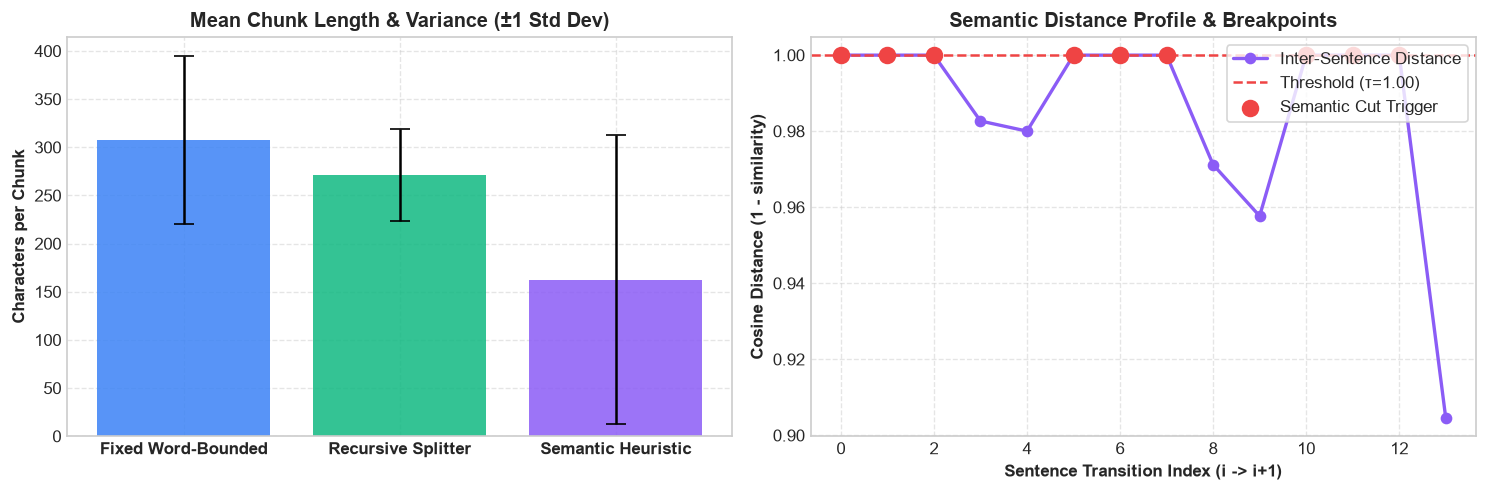

In [9]:
# Run all three chunkers on the full cleaned document
fixed_results = fixed_size_chunker_word_bounded(CLEANED_DOCUMENT, chunk_size=350, chunk_overlap=50)
rec_results = RecursiveCharacterSplitter(chunk_size=350, chunk_overlap=50).split_text(CLEANED_DOCUMENT)
sem_results, sem_distances, sem_threshold = SemanticHeuristicChunker(threshold_percentile=70.0, max_chunk_size=450).chunk(CLEANED_DOCUMENT)

def compute_metrics(name: str, chunk_list: List[Dict[str, Any]]) -> Dict[str, Any]:
    lengths = [c["char_length"] for c in chunk_list]
    return {
        "Strategy": name,
        "Total Chunks": len(chunk_list),
        "Min Chars": min(lengths) if lengths else 0,
        "Mean Chars": round(float(np.mean(lengths)), 1) if lengths else 0,
        "Max Chars": max(lengths) if lengths else 0,
        "Std Dev": round(float(np.std(lengths)), 1) if lengths else 0
    }

metrics = [
    compute_metrics("Fixed Word-Bounded", fixed_results),
    compute_metrics("Recursive Splitter", rec_results),
    compute_metrics("Semantic Heuristic", sem_results)
]

# Print Formatted Summary Table
headers = ["Strategy", "Total Chunks", "Min Chars", "Mean Chars", "Max Chars", "Std Dev"]
row_fmt = "{:<20} | {:<12} | {:<10} | {:<10} | {:<10} | {:<10}"
print(row_fmt.format(*headers))
print("-" * 82)
for m in metrics:
    print(row_fmt.format(
        m["Strategy"], m["Total Chunks"], m["Min Chars"], m["Mean Chars"], m["Max Chars"], m["Std Dev"]
    ))

# Visualization: 2-Panel Diagnostic Figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))

# Panel 1: Chunk Length Distribution by Strategy
strategies = [m["Strategy"] for m in metrics]
means = [m["Mean Chars"] for m in metrics]
std_devs = [m["Std Dev"] for m in metrics]
x_pos = np.arange(len(strategies))

bars = ax1.bar(x_pos, means, yerr=std_devs, capsize=6, color=["#3b82f6", "#10b981", "#8b5cf6"], alpha=0.85)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(strategies, fontweight="bold")
ax1.set_ylabel("Characters per Chunk", fontweight="bold")
ax1.set_title("Mean Chunk Length & Variance (±1 Std Dev)", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)

# Panel 2: Semantic Distance Curve & Breakpoints
sent_indices = np.arange(len(sem_distances))
ax2.plot(sent_indices, sem_distances, marker="o", color="#8b5cf6", linewidth=2, label="Inter-Sentence Distance")
ax2.axhline(sem_threshold, color="#ef4444", linestyle="--", linewidth=1.5, label=f"Threshold (τ={sem_threshold:.2f})")

breakpoints = np.where(sem_distances >= sem_threshold)[0]
ax2.scatter(breakpoints, sem_distances[breakpoints], color="#ef4444", s=90, zorder=5, label="Semantic Cut Trigger")

ax2.set_xlabel("Sentence Transition Index (i -> i+1)", fontweight="bold")
ax2.set_ylabel("Cosine Distance (1 - similarity)", fontweight="bold")
ax2.set_title("Semantic Distance Profile & Breakpoints", fontweight="bold")
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Step 10: Production Decision Framework & Summary

| Dimension | Fixed-Size with Overlap | Recursive Character Splitter | Semantic Boundary Heuristics |
|---|---|---|---|
| **Computational Cost** | $O(N)$ — Extremely Fast | $O(N)$ — Fast | $O(N \cdot V)$ — Moderate |
| **Boundary Respect** | Poor (cuts across sentences) | Good (respects paragraphs & lines) | Superior (adapts to topic shifts) |
| **Chunk Size Uniformity** | Extremely High (low variance) | Moderate (varies with paragraphs) | Low (adapts to thematic density) |
| **Dependencies** | Pure Python standard library | Pure Python standard library | Lightweight vectorizer / embedding model |
| **Recommended Use Case** | Uniform logs, fixed-width telemetry | General documentation, PDF/Wiki text | Complex multi-topic research papers |

---

### Core Takeaways & Engineering Best Practices:
1. **Always normalize Unicode with NFKC:** Resolves ligatures (`ﬁ` $\to$ `fi`) and typography artifacts that silently corrupt embedding recall.
2. **De-hyphenate line breaks contextually:** Recombine line-broken words (`trans-\nformer` $\to$ `transformer`) while guarding genuine hyphenated compounds (`state-of-the-art`).
3. **Recursive Splitting is the Default Baseline:** For the vast majority of RAG applications, recursive splitting with a hierarchical separator fallback (`["\n\n", "\n", " ", ""]`) produces the most balanced combination of boundary preservation and predictable token footprints.
4. **Use Semantic Chunking for Thematic Heterogeneity:** When documents contain sudden topical pivots or uneven structural formatting, statistical distance breakpoints prevent unrelated concepts from being merged into one retrieval unit.
